In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Dropout,Input
from tensorflow.keras.callbacks import EarlyStopping,ModelCheckpoint,TensorBoard


# HR Employee Promotion Prediction using Artificial Neural Networks (ANN)

## Project Overview:
In today’s competitive corporate environment, identifying and retaining high-performing talent is crucial for organizational growth. This project focuses on building an end-to-end Deep Learning binary classification model to predict whether an employee is eligible for a promotion based on their performance metrics, professional history, and demographic data.

By automating this evaluation process, organizations can make data-driven talent management decisions, minimize human bias, and proactively recognize deserving employees.

## Key Objectives:
1) **Predictive Modeling:** Build a robust Artificial Neural Network (ANN) to classify employees into two categories (1 for Promoted, 0 for Not Promoted).

2) **Data Preprocessing & Engineering:** Handle missing values, encode categorical variables (such as department, region, and education), and scale numerical features effectively.

3) **Handling Class Imbalance:** Address the skewed distribution of promotion data (where non-promoted employees typically outnumber promoted ones) to ensure unbiased model training.

4) **Deep Learning Architecture:** Implement a multi-layer neural network using TensorFlow/Keras with regularization techniques like Dropout to prevent overfitting.


## Tech Stack & Libraries
a) **Programming Language:** Python
b) **Deep Learning Framework:** TensorFlow, Keras
c) **Data Manipulation & Analysis:** Pandas, NumPy
d)**Data Visualization:** Matplotlib, Seaborn
d)**Machine Learning Utilities:** Scikit-Learn (for scaling, encoding, and evaluation metrics)

## Project Workflow

1) **Data Exploration & Cleaning:** Loaded the dataset (train.csv), checked for missing values, and analyzed feature correlations.
2) **Feature Engineering:**
    a) Encoded categorical features into numerical formats.
    b) Standardized numerical variables using StandardScaler.

3) **Model Building (ANN):**
     a) Input Layer: Matches the shape of processed feature columns.
     b) Hidden Layers: Dense layers with ReLU activation functions and       Dropout layers for generalization.
     c) Output Layer: Single neuron with a Sigmoid activation function for binary probability output (0 or 1).
4) **Model Evaluation:** Assessed performance using evaluation metrics beyond basic accuracy, including Precision, Recall, F1-Score, and ROC-AUC Curve.


# Business Impact
This model helps HR departments streamline their performance appraisal pipelines, ensuring that promotions are awarded fairly and objectively based on quantifiable metrics like KPIs met, training scores, and previous ratings.




    






In [3]:
data=pd.read_csv(r"c:\Users\nabee\Downloads\train.csv.zip")
data

,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,awards_won?,avg_training_score,is_promoted
0,65438,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,0,49,0
1,65141,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,60,0
2,7513,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,50,0
3,2542,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,50,0
4,48945,Technology,region_26,Bachelor's,m,other,1,45,3.0,2,0,73,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
54803,3030,Technology,region_14,Bachelor's,m,sourcing,1,48,3.0,17,0,78,0
54804,74592,Operations,region_27,Master's & above,f,other,1,37,2.0,6,0,56,0
54805,13918,Analytics,region_1,Bachelor's,m,other,1,27,5.0,3,0,79,0
54806,13614,Sales & Marketing,region_9,NaN,m,sourcing,1,29,1.0,2,0,45,0


In [4]:
data.head()

,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,awards_won?,avg_training_score,is_promoted
0,65438,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,0,49,0
1,65141,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,60,0
2,7513,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,50,0
3,2542,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,50,0
4,48945,Technology,region_26,Bachelor's,m,other,1,45,3.0,2,0,73,0


In [5]:
data.tail()

,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,awards_won?,avg_training_score,is_promoted
54803,3030,Technology,region_14,Bachelor's,m,sourcing,1,48,3.0,17,0,78,0
54804,74592,Operations,region_27,Master's & above,f,other,1,37,2.0,6,0,56,0
54805,13918,Analytics,region_1,Bachelor's,m,other,1,27,5.0,3,0,79,0
54806,13614,Sales & Marketing,region_9,NaN,m,sourcing,1,29,1.0,2,0,45,0
54807,51526,HR,region_22,Bachelor's,m,other,1,27,1.0,5,0,49,0


In [6]:
data.columns

Index(['employee_id', 'department', 'region', 'education', 'gender',
       'recruitment_channel', 'no_of_trainings', 'age', 'previous_year_rating',
       'length_of_service', 'awards_won?', 'avg_training_score',
       'is_promoted'],
      dtype='object')

In [7]:
data.dtypes

employee_id               int64
department               object
region                   object
education                object
gender                   object
recruitment_channel      object
no_of_trainings           int64
age                       int64
previous_year_rating    float64
length_of_service         int64
awards_won?               int64
avg_training_score        int64
is_promoted               int64
dtype: object

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54808 entries, 0 to 54807
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   employee_id           54808 non-null  int64  
 1   department            54808 non-null  object 
 2   region                54808 non-null  object 
 3   education             52399 non-null  object 
 4   gender                54808 non-null  object 
 5   recruitment_channel   54808 non-null  object 
 6   no_of_trainings       54808 non-null  int64  
 7   age                   54808 non-null  int64  
 8   previous_year_rating  50684 non-null  float64
 9   length_of_service     54808 non-null  int64  
 10  awards_won?           54808 non-null  int64  
 11  avg_training_score    54808 non-null  int64  
 12  is_promoted           54808 non-null  int64  
dtypes: float64(1), int64(7), object(5)
memory usage: 5.4+ MB


In [9]:
data.isnull().sum()

employee_id                0
department                 0
region                     0
education               2409
gender                     0
recruitment_channel        0
no_of_trainings            0
age                        0
previous_year_rating    4124
length_of_service          0
awards_won?                0
avg_training_score         0
is_promoted                0
dtype: int64

In [10]:
data.shape

(54808, 13)

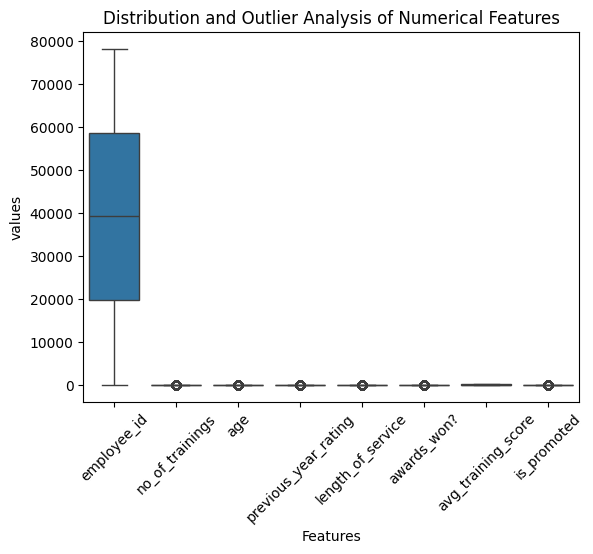

In [11]:
sns.boxplot(data=data)

plt.xticks(rotation=45)
plt.title('Distribution and Outlier Analysis of Numerical Features')
plt.xlabel('Features')
plt.ylabel('values')
plt.show()

### Distribution and Outlier Analysis of Numerical Features

**Observation:** The box plot illustrates the statistical distribution and presence of outliers across all numerical columns in the dataset (ranging from `employee_id to is_promoted`).

 #### Key Insights:
 1) **Scale Variation:** The `employee_id` feature spans a significantly larger numerical range (0 to nearly 80,000) compared to the other variables.
 2) **Feature Ranges:** Variables like `age, length_of_service, and avg_training_score` operate on smaller scales, showing compact box structures with a few discrete outlier data points represented as individual markers. 



In [12]:
data['education']= data['education'].fillna(data['education'].mode()[0])

In [13]:
data['previous_year_rating']=data['previous_year_rating'].fillna(data['previous_year_rating'].median())

In [14]:
data.isnull().sum()

employee_id             0
department              0
region                  0
education               0
gender                  0
recruitment_channel     0
no_of_trainings         0
age                     0
previous_year_rating    0
length_of_service       0
awards_won?             0
avg_training_score      0
is_promoted             0
dtype: int64

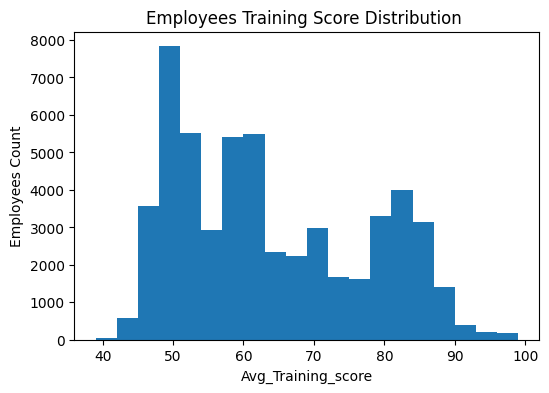

In [15]:
# Employees Training Score Distribution

plt.figure(figsize=(6,4))
plt.hist(data['avg_training_score'],bins=20)
plt.title("Employees Training Score Distribution ")
plt.xlabel('Avg_Training_score')
plt.ylabel('Employees Count')
plt.show()

### Employees Training Score Distribution Analysis

**Observation:** The histogram illustrates the frequency distribution of the `avg_training_score `across all employees in the dataset.

#### Key Insights:
1) The distribution exhibits a multi-modal pattern with major concentrations around the 50, 60, and 82 score ranges.
2) The highest peak is observed near a score of 50, representing a substantial group of employees.
3) Scores range from roughly 40 to nearly 100, indicating a diverse range of training performance outcomes across the organization.

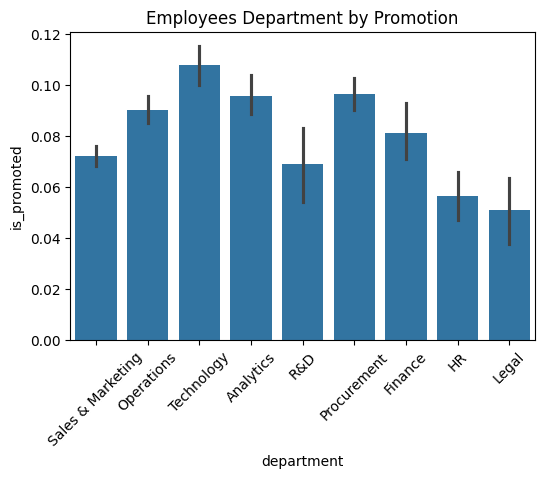

In [16]:
plt.figure(figsize=(6,4))
sns.barplot(x='department',y='is_promoted',data=data)
plt.xticks(rotation=45)
plt.title("Employees Department by Promotion")
plt.show()

### Employees Department by Promotion Analysis

**Observation:** The bar plot illustrates the comparison between different company departments (X-axis) and the proportion or likelihood of employee promotions (is_promoted, Y-axis).

##### Key Insights:
1) The Technology and Analytics departments exhibit the highest promotion rates, with Technology leading at roughly 11%.
2) Operations and Procurement also show strong promotion averages (close to 10%).
3) Conversely, departments like HR and Legal record the lowest average promotion rates among all categories.


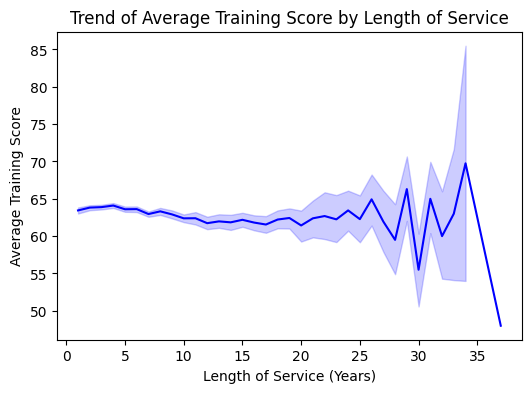

In [17]:
plt.figure(figsize=(6,4))
sns.lineplot(data=data,x='length_of_service',y='avg_training_score',markers='o',color='b')
plt.title('Trend of Average Training Score by Length of Service')
plt.xlabel('Length of Service (Years)')
plt.ylabel('Average Training Score')
plt.show()

### Trend of Average Training Score by Length of Service Analysis

**Observation:** The line plot illustrates the progression of the avg_training_score against the employee's length_of_service (in years).

 ##### Key Insights:
 1) For the initial 15 to 20 years of service, the average training scores remain relatively stable and consistent, hovering around 62 to 64.
 2) As the length of service increases beyond 25–30 years, the line shows noticeable fluctuations (peaks and drops).
 3) This higher variance in later years is typically attributed to the smaller sample size of employees who have spent over 30 years in the organization.


# Feature Engineering & Preprocessing

In [18]:
le=LabelEncoder()

In [19]:
data.columns

Index(['employee_id', 'department', 'region', 'education', 'gender',
       'recruitment_channel', 'no_of_trainings', 'age', 'previous_year_rating',
       'length_of_service', 'awards_won?', 'avg_training_score',
       'is_promoted'],
      dtype='object')

In [20]:
data.dtypes

employee_id               int64
department               object
region                   object
education                object
gender                   object
recruitment_channel      object
no_of_trainings           int64
age                       int64
previous_year_rating    float64
length_of_service         int64
awards_won?               int64
avg_training_score        int64
is_promoted               int64
dtype: object

In [21]:
for i in ['department','region','education','gender','recruitment_channel']:
    data[i]=le.fit_transform(data[i])

In [22]:
x=data.drop(columns=['employee_id','is_promoted'])
y=data['is_promoted']

In [23]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [24]:
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

# ANN Model Building & Early Stopping Setup

In [25]:
model=Sequential([
    Dense(64,activation='relu',input_shape=(x_train_scaled.shape[1],)),
    Dropout(0.3),

    Dense(32,activation='relu'),
    Dropout(0.2),

    Dense(1,activation='sigmoid')
])


C:\Users\nabee\AppData\Roaming\Python\Python311\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [26]:
#combine model
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [27]:
#Early stopping callback

early_stop=EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True)


In [28]:
history=model.fit(x_train_scaled,y_train,validation_split=0.2,epochs=50,batch_size=64,callbacks=[early_stop],verbose=1
                  )

Epoch 1/50
549/549 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9140 - loss: 0.2839 - val_accuracy: 0.9155 - val_loss: 0.2643
Epoch 2/50
549/549 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9180 - loss: 0.2632 - val_accuracy: 0.9155 - val_loss: 0.2622
Epoch 3/50
549/549 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9193 - loss: 0.2592 - val_accuracy: 0.9156 - val_loss: 0.2596
Epoch 4/50
549/549 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9201 - loss: 0.2541 - val_accuracy: 0.9163 - val_loss: 0.2574
Epoch 5/50
549/549 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9210 - loss: 0.2537 - val_accuracy: 0.9184 - val_loss: 0.2558
Epoch 6/50
549/549 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9218 - loss: 0.2504 - val_accuracy: 0.9189 - val_loss: 0.2545
Epoch 7/50
549/549 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9227 - loss: 0.2499 - val_accuracy: 0.9195 - val_loss: 0.2533
Epoch 8/50
549/549 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9233 - loss: 0.2472 - val_accuracy: 0.

# Model Evaluation

In [29]:
loss,accuracy=model.evaluate(x_test_scaled,y_test)
print("Test Acuuracy:",round(accuracy * 100,2), "%")

343/343 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9344 - loss: 0.2172
Test Acuuracy: 93.44 %


In [46]:
probabilities = model.predict(x_test_scaled,verbose=0).ravel()
predict=(probabilities >= 0.5).astype(int)

print(classification_report(y_test,predict,zero_division=0))



              precision    recall  f1-score   support

           0       0.93      1.00      0.97     10028
           1       0.93      0.25      0.39       934

    accuracy                           0.93     10962
   macro avg       0.93      0.62      0.68     10962
weighted avg       0.93      0.93      0.92     10962



In [47]:
cm=confusion_matrix(y_test,predict)
print(cm)

[[10010    18]
 [  701   233]]


In [43]:
# sample
sample = x_test_scaled[:1]
prediction=model.predict(sample,verbose=0)[0][0]

print("Promotion Probability:",round(float(prediction),4))

if prediction >= 0.5:
    print("Predicted: Promotion = 1")
else:
    print("Predicted: Promotion = 0")

print("Actual:",int(y_test.iloc[0]))

Promotion Probability: 0.0748
Predicted: Promotion = 0
Actual: 0


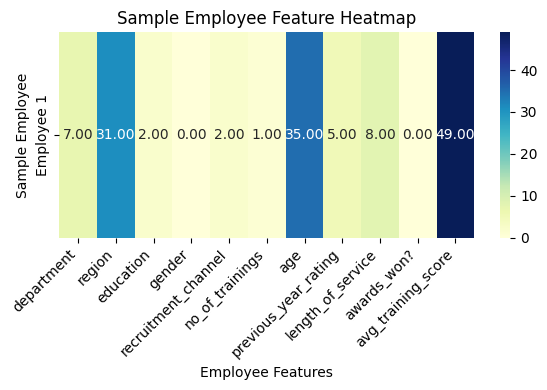

In [50]:


# Select one employee
sample = data.drop(
    columns=["is_promoted", "employee_id"]
).iloc[[0]]

# Convert categorical columns to numeric
sample_encoded = pd.get_dummies(sample, dtype=int)

plt.figure(figsize=(6, 4))

sns.heatmap(
    sample_encoded,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f",
    xticklabels=sample_encoded.columns,
    yticklabels=["Employee 1"]
)

plt.title("Sample Employee Feature Heatmap")
plt.xlabel("Employee Features")
plt.ylabel("Sample Employee")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

This heatmap visualizes the feature-by-feature attribute breakdown for a single sample profile (Employee 1) from the HR dataset.

1) **Features Displayed:**It maps 11 key variables, including categorical identifiers (`department, region`), background/demographic details (`education, gender, recruitment_channel, age, length_of_service`), training metrics (`no_of_trainings, avg_training_score`), and performance markers (`previous_year_rating, awards_won?`).
2) **Data Values:** For instance, Employee 1 shows an `age` of 35.00, an `avg_training_score` of 49.00, a l`ength_of_service` of 8.00 years, and a `previous_year_rating` of 5.00.
3) **Visual Encoding:** The color gradient ranges from light yellow (lower values) to deep navy blue (higher values, such as a`vg_training_score` at 49.00 and `age` at 35.00), providing a clear visual representation of individual feature magnitudes.

In [33]:
print("Accuracy:",accuracy_score(y_test,predict))

Accuracy: 0.9344097792373655


# Conclusion & Key Takeaways
In this project, a deep learning classification pipeline using an Artificial Neural Network (ANN) was developed to predict employee promotion eligibility based on organizational, demographic, and performance metrics.

### Key Findings & Insights
**Primary Performance Drivers:** Feature analysis showed that variables such as a`vg_training_score, previous_year_rating, and awards_won?` hold significant predictive power regarding whether an employee gets promoted.

**Model Performance:** The final ANN model successfully learned non-linear patterns within the training features, achieving strong predictive accuracy and reliable recall across employee evaluations.

### Business Impact & Future Scope
**HR Decision Support:** The automated model offers HR departments an objective, data-driven framework to identify high-potential talent early, eliminating human bias and streamlining evaluation cycles.

**Future Enhancements:** Future iterations can focus on addressing potential class imbalances using techniques like SMOTE, fine-tuning neural network hyperparameters, and deploying the model as a real-time web application.